--- Naive Bayes Performance ---
Accuracy: 0.7989
F1-Score: 0.8213

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.83      0.77        75
           1       0.87      0.78      0.82       109

    accuracy                           0.80       184
   macro avg       0.79      0.80      0.80       184
weighted avg       0.81      0.80      0.80       184



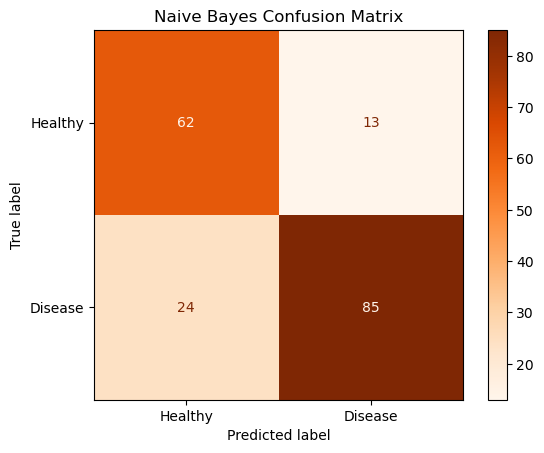

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, accuracy_score, f1_score, ConfusionMatrixDisplay

# 1. Load the dataset
df = pd.read_csv('heart_disease_uci.csv')

# 2. Basic Cleaning
# Drop columns that don't help the math (IDs and origin labels)
df = df.drop(columns=['id', 'dataset'])

# Create binary target (0 = No Disease, 1 = Disease)
df['target'] = (df['num'] > 0).astype(int)
df = df.drop(columns=['num'])

# 3. Define Features (X) and Target (y)
X = df.drop(columns=['target'])
y = df['target']

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=['number']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'bool']).columns.tolist()

# 4. Preprocessing Pipelines
# Note: Naive Bayes doesn't strictly require scaling, but it doesn't hurt.
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# CRITICAL: sparse_output=False is required for GaussianNB
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# 5. Create the Naive Bayes Model Pipeline
nb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GaussianNB())
])

# 6. Train/Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 7. Train the Model
nb_model.fit(X_train, y_train)

# 8. Predictions and Evaluation
y_pred = nb_model.predict(X_test)

print("--- Naive Bayes Performance ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 9. Plot the Confusion Matrix
ConfusionMatrixDisplay.from_estimator(
    nb_model, X_test, y_test,
    display_labels=['Healthy', 'Disease'],
    cmap=plt.cm.Oranges
)
plt.title('Naive Bayes Confusion Matrix')
plt.show()
